# How much does a hit look like its alert?

Each row in `Hits.csv` is a watchlist profile that the screening system already attached to one row in `Alerts.csv`. The shared key is `alert_id`. One alert has between 1 and 15 hits. The decision is not "find a match somewhere in the other file." The decision is "for this pair, how confident am I that the profile is the screened customer?"

Two corrections to the setup, because they change the model:

- A hit is not always a sanctioned person. The profile can be sanctions, PEP, enforcement, adverse media, or a company. An alert is the customer as the screener saw them, not a member of a separate list.
- Most hit columns have no twin in the alert. `profile_notes`, `sources`, and `identifiers` describe the watchlist profile. `account_ref`, `email`, and `login_handle` are links into the bank. A regression can only use characteristics that exist on both sides of the pair, or a score the screener already computed.

## The approach

1. Join every hit to its alert. That produces 819 pairs.
2. For each characteristic that both sides can carry, mark the pair `agree`, `contradict`, or `unknown`. Unknown has to stay unknown. A blank date of birth is not a mismatch, and most dates and countries are blank.
3. Look at the 50 practice labels and see which of those marks actually differ between `SAME_ENTITY`, `DIFFERENT_ENTITY`, and `REVIEW`.
4. Fit a logistic regression on those marks. Logistic regression is the right regression here because the training target is binary and the quantity we want back is a probability. A linear regression on 0/1 can predict 1.4 or -0.2, which is not a confidence.

The probability is a first confidence that the hit is the same entity as the screened customer. It is fit on 50 answers. Those answers were made with customer, KYC, and note records that are not in these two files, so a high probability is not yet a decision.

## Setup

Run this from the repository root, in `.Hack_venv`. The notebook extras are `scikit-learn` and `matplotlib`:

```bash
source .Hack_venv/bin/activate
python -m pip install -e ".[notebook]"
```

In [1]:
from pathlib import Path
import re
import unicodedata

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedKFold, cross_val_predict

pd.set_option("display.max_colwidth", 80)
pd.set_option("display.width", 120)


def find_root() -> Path:
    here = Path.cwd().resolve()
    for candidate in [here, *here.parents]:
        if (candidate / "data" / "Hits.csv").is_file():
            return candidate
    raise FileNotFoundError("Run this notebook from the repository, so data/Hits.csv is visible.")


ROOT = find_root()
ROOT

PosixPath('/Users/remij/Documents/GitHub/Cursor_Hackathon')

## Join hits to alerts

`alert_id` is unique on an alert and repeated on its hits. The merge is checked as many-to-one so a duplicated alert key fails loudly instead of multiplying rows.

In [2]:
alerts = pd.read_csv(ROOT / "data" / "Alerts.csv", dtype=str, keep_default_na=False)
hits = pd.read_csv(ROOT / "data" / "Hits.csv", dtype=str, keep_default_na=False)
labels = pd.read_csv(ROOT / "data" / "Practice_labels.csv", dtype=str, keep_default_na=False)

paired = hits.rename(
    columns={"name": "hit_name", "entity_type": "hit_entity_type"}
).merge(
    alerts.rename(columns={"entity_type": "alert_entity_type"}),
    on="alert_id",
    how="left",
    validate="many_to_one",
)

hits_per_alert = paired.groupby("alert_id").size()
print(f"{len(alerts)} alerts, {len(paired)} hit-alert pairs")
print(hits_per_alert.describe().round(2).to_string())
print("practice labels that join to a hit:", labels["hit_id"].isin(paired["hit_id"]).sum())

440 alerts, 819 hit-alert pairs
count    440.00
mean       1.86
std        2.46
min        1.00
25%        1.00
50%        1.00
75%        1.00
max       15.00
practice labels that join to a hit: 50


## Which columns can speak to each other?

| Comparison | Alert field | Hit fields | What "agree" means in this first pass |
| --- | --- | --- | --- |
| Name | `customer_name` | `hit_name`, `aliases` | At least two name parts match, or every part of the shorter name matches. Parts are letters only, case and accents ignored. Single letters and digits are dropped. |
| Date of birth | `dob` | `dobs` | Some listed hit date is within one year of the screened date, and the month or day does not clash when both sides have one. One agreeing date is enough. |
| Country | `country` | `countries`, `nationality`, `citizenship` | The screened country equals one of those values after lower-casing. `International` and `Europe` are ignored. |
| City | `city` | `addresses`, `place_of_birth` | The screened city string occurs in the hit's address text. |
| Entity type | `alert_entity_type` | `hit_entity_type` | Both say `Individual` or both say `Company`. |

This is a thinner rule than the SOP. It does not use name variants (`Bill`/`William`), edit distance, ages buried in profile notes, or web search. Blank against blank, and blank against a value, are both `unknown`.

`match_score` is already the screener's name-similarity score. Every hit in this file sits between 90 and 100, because a weak name never became a hit. It is a column to inspect, not a characteristic of the customer.

In [3]:
def fold(text: str) -> str:
    text = unicodedata.normalize("NFKD", text or "")
    text = "".join(char for char in text if not unicodedata.combining(char))
    text = text.lower()
    text = re.sub(r"\([^)]*\)", " ", text)
    text = re.sub(r"[^a-z0-9\s]", " ", text)
    return " ".join(text.split())


def name_tokens(text: str) -> set[str]:
    return {token for token in fold(text).split() if len(token) > 1 and not token.isdigit()}


def listed_values(text: str) -> set[str]:
    return {fold(part) for part in re.split(r"[;|]", text or "") if fold(part)}


DATE_RE = re.compile(r"(\d{4})(?:-(\d{2})(?:-(\d{2}))?)?")
IGNORED_PLACES = {"international", "europe"}


def partial_dates(text: str) -> list[tuple[int, int | None, int | None]]:
    parsed = []
    for year, month, day in DATE_RE.findall(text or ""):
        parsed.append((int(year), int(month) if month else None, int(day) if day else None))
    return parsed


def dates_agree(
    left: tuple[int, int | None, int | None],
    right: tuple[int, int | None, int | None],
) -> bool:
    if abs(left[0] - right[0]) > 1:
        return False
    if left[0] == right[0] and left[1] and right[1] and left[1] != right[1]:
        return False
    if (
        left[0] == right[0]
        and left[1]
        and right[1]
        and left[1] == right[1]
        and left[2]
        and right[2]
        and left[2] != right[2]
    ):
        return False
    return True


def name_comparison(customer: str, hit_name: str, aliases: str) -> str:
    left = name_tokens(customer)
    right = name_tokens(hit_name) | name_tokens(aliases)
    if not left or not right:
        return "unknown"
    shared = left & right
    shorter = min(len(left), len(right))
    if len(shared) >= 2 or len(shared) == shorter:
        return "agree"
    return "contradict"


def dob_comparison(alert_dob: str, hit_dobs: str) -> str:
    left, right = partial_dates(alert_dob), partial_dates(hit_dobs)
    if not left or not right:
        return "unknown"
    if any(dates_agree(alert_date, hit_date) for alert_date in left for hit_date in right):
        return "agree"
    return "contradict"


def country_comparison(alert_country: str, *hit_fields: str) -> str:
    left = listed_values(alert_country)
    right: set[str] = set()
    for field in hit_fields:
        right |= listed_values(field)
    right -= IGNORED_PLACES
    if not left or not right:
        return "unknown"
    if left & right:
        return "agree"
    return "contradict"


def city_comparison(city: str, addresses: str, place_of_birth: str) -> str:
    city_text = fold(city)
    blob = fold(f"{addresses} {place_of_birth}")
    if not city_text or not blob:
        return "unknown"
    if city_text in blob:
        return "agree"
    return "contradict"


def entity_comparison(alert_type: str, hit_type: str) -> str:
    if not alert_type or not hit_type:
        return "unknown"
    if alert_type == hit_type:
        return "agree"
    return "contradict"


comparisons = pd.DataFrame(
    {
        "name_cmp": [
            name_comparison(row.customer_name, row.hit_name, row.aliases)
            for row in paired.itertuples(index=False)
        ],
        "dob_cmp": [
            dob_comparison(row.dob, row.dobs) for row in paired.itertuples(index=False)
        ],
        "country_cmp": [
            country_comparison(row.country, row.countries, row.nationality, row.citizenship)
            for row in paired.itertuples(index=False)
        ],
        "city_cmp": [
            city_comparison(row.city, row.addresses, row.place_of_birth)
            for row in paired.itertuples(index=False)
        ],
        "entity_cmp": [
            entity_comparison(row.alert_entity_type, row.hit_entity_type)
            for row in paired.itertuples(index=False)
        ],
    },
    index=paired.index,
)
paired = pd.concat([paired, comparisons], axis=1)

coverage = pd.DataFrame({column: paired[column].value_counts() for column in comparisons.columns}).fillna(0).astype(int)
coverage = coverage.reindex(["agree", "contradict", "unknown"])
coverage

,name_cmp,dob_cmp,country_cmp,city_cmp,entity_cmp
agree,636,81,51,12,818
contradict,183,22,113,139,1
unknown,0,716,655,668,0


The counts above are the reason not to drop blank cells or to code them as zero. Date of birth is unknown on most pairs, because the hit often has no `dobs` value or the alert has no `dob`. Country and city are unknown even more often. Name and entity type are almost always known, and name agreement is common, because the screener already required the names to look similar before it wrote the hit.

Entity type barely varies: a person is almost never paired with a company. It cannot carry a regression on its own.

## What the 50 answered hits say

`Practice_labels.csv` is the only file with a decision. Each label points at a `hit_id`. The cross-tabs below are the direct answer to "which comparison hits": a useful column has a different mix of agree / contradict / unknown for `SAME_ENTITY` than for `DIFFERENT_ENTITY`. `REVIEW` is its own outcome. It is not a medium score.

In [4]:
labeled = paired.merge(
    labels[["hit_id", "decision", "reason_codes"]],
    on="hit_id",
    how="inner",
    validate="one_to_one",
)
print(labeled["decision"].value_counts().to_string())
print()
for column in ["name_cmp", "dob_cmp", "country_cmp", "city_cmp", "entity_cmp"]:
    print(column)
    print(pd.crosstab(labeled[column], labeled["decision"], margins=True))
    print()

labeled["match_score_num"] = pd.to_numeric(labeled["match_score"])
print("mean screener match_score by decision")
print(labeled.groupby("decision")["match_score_num"].mean().round(2).to_string())

decision
DIFFERENT_ENTITY    28
SAME_ENTITY         12
REVIEW              10

name_cmp
decision    DIFFERENT_ENTITY  REVIEW  SAME_ENTITY  All
name_cmp                                              
agree                     20      10           11   41
contradict                 8       0            1    9
All                       28      10           12   50

dob_cmp
decision    DIFFERENT_ENTITY  REVIEW  SAME_ENTITY  All
dob_cmp                                               
agree                      1       0            3    4
contradict                 2       0            0    2
unknown                   25      10            9   44
All                       28      10           12   50

country_cmp
decision     DIFFERENT_ENTITY  REVIEW  SAME_ENTITY  All
country_cmp                                            
agree                       0       2            2    4
contradict                  7       0            0    7
unknown                    21       8           10   39
All  

Read the cross-tabs this way. The horizontal groups are the practice decisions. Each row is the comparison result. A comparison is doing work when `contradict` piles up under `DIFFERENT_ENTITY` and `agree` piles up under `SAME_ENTITY`.

Name agreement will not do much of that work. These rows are already screening hits, so the names were similar enough to be raised. The screener's `match_score` has the same problem: the scores only cover 90 to 100. Date of birth and country are where a contradiction can still appear, and only when both sides recorded a value.

The chart makes that comparison easier to see. The vertical axis is the share of labeled hits, not a count, so the three decisions can be compared even though `DIFFERENT_ENTITY` has more rows. With 12, 10, and 28 labels, moving two rows changes a bar by a lot.

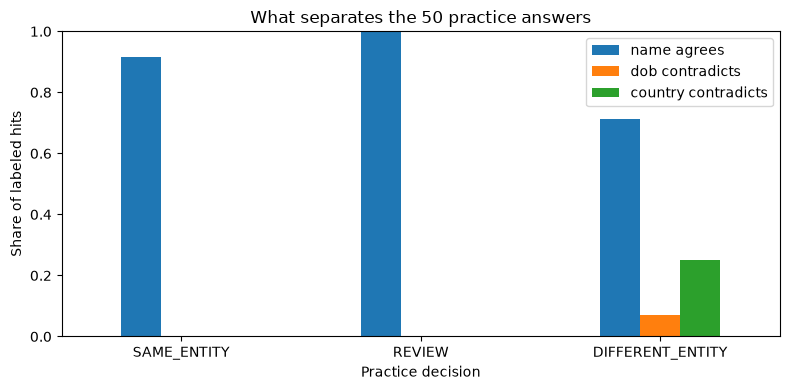

,name agrees,dob contradicts,country contradicts
decision,,,
SAME_ENTITY,0.92,0.00,0.00
REVIEW,1.00,0.00,0.00
DIFFERENT_ENTITY,0.71,0.07,0.25


In [5]:
plot_features = {
    "name agrees": labeled["name_cmp"].eq("agree"),
    "dob contradicts": labeled["dob_cmp"].eq("contradict"),
    "country contradicts": labeled["country_cmp"].eq("contradict"),
}
decision_order = ["SAME_ENTITY", "REVIEW", "DIFFERENT_ENTITY"]
rates = pd.DataFrame(
    {name: flags.groupby(labeled["decision"]).mean() for name, flags in plot_features.items()}
).reindex(decision_order)

ax = rates.plot(kind="bar", figsize=(8, 4), rot=0, ylim=(0, 1))
ax.set_xlabel("Practice decision")
ax.set_ylabel("Share of labeled hits")
ax.set_title("What separates the 50 practice answers")
ax.legend(title=None)
plt.tight_layout()
plt.show()
rates.round(2)

## Logistic regression

The model sees one row per labeled hit. Each comparison becomes two indicators, `agree` and `contradict`. The reference case is `unknown`: both indicators are 0, so a missing date does not look like a conflict.

The fitted number is

`P(SAME_ENTITY | the indicators)`.

`REVIEW` and `DIFFERENT_ENTITY` are both coded 0 for this first fit. That is a blunt choice. It asks only "does this look like the hits the practice set confirmed?" A later model can treat `REVIEW` as its own class. City stays out of the fit because the screened city is usually blank, so the indicator would rest on a handful of labels. Entity type stays out because it almost never contradicts.

Fifty rows cannot support an unpenalised regression of many coefficients. The fit is L2-penalised logistic regression, with the 12 confirmed hits up-weighted so the model does not just predict "not the same" every time. Coefficients are directional evidence. They are not precise effects.

The probabilities used to judge the fit are out-of-fold: each labeled hit is scored by a model that did not train on it. The reported AUC is for that out-of-fold score. With about two confirmed hits per fold, the AUC will move if the split changes.

In [6]:
FEATURE_COLUMNS = [
    "name_agree",
    "dob_agree",
    "dob_contradict",
    "country_agree",
    "country_contradict",
]


def indicators(frame: pd.DataFrame) -> pd.DataFrame:
    built = pd.DataFrame(index=frame.index)
    for column, prefix in [
        ("name_cmp", "name"),
        ("dob_cmp", "dob"),
        ("country_cmp", "country"),
    ]:
        built[f"{prefix}_agree"] = frame[column].eq("agree").astype(int)
        built[f"{prefix}_contradict"] = frame[column].eq("contradict").astype(int)
    return built


features = indicators(paired)
labeled_x = features.loc[labeled.index, FEATURE_COLUMNS]
same_entity = labeled["decision"].eq("SAME_ENTITY").astype(int)

model = LogisticRegression(C=1.0, class_weight="balanced", max_iter=1000, random_state=0)
model.fit(labeled_x, same_entity)

coefficients = pd.Series(model.coef_[0], index=FEATURE_COLUMNS, name="coefficient")
print(f"intercept {model.intercept_[0]:.3f}")
print(coefficients.round(3).to_string())
print()

folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
held_out = cross_val_predict(
    model,
    labeled_x,
    same_entity,
    cv=folds,
    method="predict_proba",
)[:, 1]
print(f"out-of-fold AUC for SAME_ENTITY: {roc_auc_score(same_entity, held_out):.2f}")
labeled = labeled.copy()
labeled["confidence_held_out"] = held_out
print()
print(labeled.groupby("decision")["confidence_held_out"].agg(["count", "mean", "median"]).round(3))

intercept 0.389
name_agree           -0.664
dob_agree             0.960
dob_contradict       -0.245
country_agree         0.334
country_contradict   -0.037

out-of-fold AUC for SAME_ENTITY: 0.48

                  count   mean  median
decision                              
DIFFERENT_ENTITY     28  0.483   0.450
REVIEW               10  0.465   0.439
SAME_ENTITY          12  0.481   0.467


The fit does not separate the practice labels. The out-of-fold AUC is 0.48, which is a coin flip, and the mean confidence is about 0.48 for `SAME_ENTITY` and 0.48 for `DIFFERENT_ENTITY`.

The coefficients are not a reliable ranking of the columns:

- 44 of the 50 labels have an unknown date comparison, and 39 have an unknown country. Most training rows are the same vector: the name agrees, and the date and country are missing.
- `name_agree` comes out negative. That does not mean a matching name makes a hit less plausible. Eleven of the twelve confirmed hits agree on name, and so do 20 of the 28 cleared hits. With almost nothing else varying, the penalty lets that indicator absorb noise.
- Every labeled country contradiction is a cleared hit (7 of them), but `country_contradict` shrinks to about zero. Seven rows are not enough for this penalty to keep a large weight.
- `dob_agree` is the one coefficient with the expected direction and any size. Only four labeled hits have an agreeing date.

Keep the cross-tabs, not the coefficients. In these 50 answers, a country contradiction never appears on a confirmed or review hit, and both date contradictions are cleared hits. The screener's `match_score` averages 99.3 on confirmed hits and 95.6 on cleared hits. That gap is real and small, inside a band that only runs from 90 to 100, which is why it was left out of the fit.


## A confidence for every hit

Refit on all 50 labels, then score all 819 pairs. The new column is `confidence_same`. It is the model's probability that the hit would be labeled `SAME_ENTITY`, using only name, date of birth, and country agreement with the alert.

Hits that share an `alert_id` can receive very different confidences. That is the point of scoring pairs rather than scoring the alert once.

In [7]:
paired = paired.copy()
paired["confidence_same"] = model.predict_proba(features[FEATURE_COLUMNS])[:, 1]

print(paired["confidence_same"].describe().round(3).to_string())
print()
print("pairs in each confidence band")
print(pd.cut(paired["confidence_same"], bins=[0, 0.25, 0.5, 0.75, 1], include_lowest=True).value_counts().sort_index().to_string())

count    819.000
mean       0.492
std        0.103
min        0.364
25%        0.432
50%        0.432
75%        0.587
max        0.794

pairs in each confidence band
confidence_same
(-0.001, 0.25]      0
(0.25, 0.5]       552
(0.5, 0.75]       231
(0.75, 1.0]        36


### One alert, five hits

Alert `A-3BCFFF` is a screened person, Christopher Paul George, born 1951-09-17, with country Netherlands and city Munich. Five profiles were attached to that alert. Two of them have practice answers, both `DIFFERENT_ENTITY`: one because the date of birth clashes, one because the country clashes. The model used below is refit without this alert, so those two answers are not in the training rows for this table.

In [8]:
example_id = "A-3BCFFF"
holdout = labeled["alert_id"] != example_id
example_model = LogisticRegression(C=1.0, class_weight="balanced", max_iter=1000, random_state=0)
example_model.fit(labeled_x.loc[holdout], same_entity.loc[holdout])

example = paired.loc[paired["alert_id"].eq(example_id)].copy()
example["confidence_same"] = example_model.predict_proba(
    features.loc[example.index, FEATURE_COLUMNS]
)[:, 1]
example = example.merge(labels[["hit_id", "decision"]], on="hit_id", how="left")
example["decision"] = example["decision"].replace("", pd.NA)

columns = [
    "hit_id",
    "hit_name",
    "dobs",
    "countries",
    "name_cmp",
    "dob_cmp",
    "country_cmp",
    "city_cmp",
    "decision",
    "confidence_same",
]
example[columns].sort_values("confidence_same", ascending=False).reset_index(drop=True)

,hit_id,hit_name,dobs,countries,name_cmp,dob_cmp,country_cmp,city_cmp,decision,confidence_same
0,H-E2C400,Christopher George,,United States,agree,unknown,contradict,contradict,NaN,0.440317
1,H-DA8F86,George Paul,,Pakistan,agree,unknown,contradict,contradict,NaN,0.440317
2,H-202F67,Christopher George,,Australia,agree,unknown,contradict,contradict,NaN,0.440317
3,H-F2AEA4,Paul Christopher,,Ireland,agree,unknown,contradict,contradict,DIFFERENT_ENTITY,0.440317
4,H-CF5228,Christopher Paul George,1980-11-11,United States,agree,contradict,contradict,contradict,DIFFERENT_ENTITY,0.381591


### How to read that table

Four of the five profiles get the same confidence, 0.44. Their name agrees, their date is unknown, and their country contradicts the Netherlands, so the model sees one identical row four times. The fifth profile, `H-CF5228`, repeats the screened name exactly and was born in 1980, against a screened date in 1951. That date contradiction lowers its confidence to 0.38. The practice label on that hit is `DOB_MISMATCH`. The other labeled hit, `H-F2AEA4`, is cleared for a location clash, but it sits in the tied group: country contradiction did not receive a weight large enough to move it, and the city Munich is not in the model.

This is the limitation in one alert. The comparison can demote a hit when a recorded date clashes. It cannot rank the remaining namesakes, because the screened country disagrees with all of them and the screened city is unused.

## What this confidence is not

`confidence_same` on the full 819 pairs only runs from about 0.36 to 0.79, and most pairs sit near 0.43 or 0.59. The score barely moves because the screened date and country are blank on most alerts, so those indicators stay at the reference case.

The number is a match between the screened alert and the watchlist profile. It is not yet a match against the customer. Several different people with similar names then receive the same confidence. The SOP says the opposite of that shortcut: follow the account, login, or email into the customer records, and let an approved identity check outrank the screened name.

The next model should not add more hit columns to this regression. It should add features from `Customers.csv`, `KYC_checks.csv`, and `Notes.csv`, joined along the path the alert actually carries, and only then refit. Until those features exist, use the agree / contradict / unknown marks as a filter, and do not treat `confidence_same` as a decision.


In [9]:
# Name only. Alert column: customer_name. Hit column: name.
# Aliases are not included. Agree means at least two parts match, or every part of the shorter name matches.

def name_coverage(customer: str, hit_name: str) -> float:
    left, right = name_tokens(customer), name_tokens(hit_name)
    if not left or not right:
        return float("nan")
    return len(left & right) / min(len(left), len(right))


name_only = paired[["hit_id", "alert_id", "customer_name", "hit_name"]].copy()
name_only["name_only_cmp"] = [
    name_comparison(customer, hit_name, "")
    for customer, hit_name in zip(name_only["customer_name"], name_only["hit_name"], strict=True)
]
name_only["name_coverage"] = [
    name_coverage(customer, hit_name)
    for customer, hit_name in zip(name_only["customer_name"], name_only["hit_name"], strict=True)
]

print(name_only["name_only_cmp"].value_counts().to_string())
print("pairs whose result changes once aliases are removed:", int((name_only["name_only_cmp"] != paired["name_cmp"]).sum()))
print()

name_labeled = name_only.merge(labels[["hit_id", "decision"]], on="hit_id", how="inner", validate="one_to_one")
print(pd.crosstab(name_labeled["name_only_cmp"], name_labeled["decision"], margins=True))
print()
print(name_labeled.groupby("decision")["name_coverage"].agg(["count", "mean", "median"]).round(3))
print()

coverage = name_labeled[["name_coverage"]]
is_same = name_labeled["decision"].eq("SAME_ENTITY").astype(int)
name_model = LogisticRegression(C=1.0, class_weight="balanced", max_iter=1000, random_state=0)
name_model.fit(coverage, is_same)
print(f"intercept {name_model.intercept_[0]:.3f}")
print(f"name_coverage coefficient {name_model.coef_[0, 0]:.3f}")

held_out_name = cross_val_predict(
    name_model,
    coverage,
    is_same,
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=0),
    method="predict_proba",
)[:, 1]
print(f"out-of-fold AUC from name coverage alone: {roc_auc_score(is_same, held_out_name):.2f}")
name_labeled = name_labeled.copy()
name_labeled["confidence_same"] = held_out_name
print(name_labeled.groupby("decision")["confidence_same"].agg(["count", "mean"]).round(3))
print()

name_only.loc[
    name_only["alert_id"].eq("A-3BCFFF"),
    ["hit_id", "customer_name", "hit_name", "name_only_cmp", "name_coverage"],
].sort_values("name_coverage", ascending=False).reset_index(drop=True)

name_only_cmp
agree         600
contradict    218
unknown         1
pairs whose result changes once aliases are removed: 37

decision       DIFFERENT_ENTITY  REVIEW  SAME_ENTITY  All
name_only_cmp                                            
agree                        19      10           11   40
contradict                    9       0            1   10
All                          28      10           12   50

                  count   mean  median
decision                              
DIFFERENT_ENTITY     28  0.744     1.0
REVIEW               10  1.000     1.0
SAME_ENTITY          12  0.931     1.0

intercept -0.727
name_coverage coefficient 0.833
out-of-fold AUC from name coverage alone: 0.53
                  count   mean
decision                      
DIFFERENT_ENTITY     28  0.485
REVIEW               10  0.523
SAME_ENTITY          12  0.507



,hit_id,customer_name,hit_name,name_only_cmp,name_coverage
0,H-E2C400,Christopher Paul George,Christopher George,agree,1.0
1,H-DA8F86,Christopher Paul George,George Paul,agree,1.0
2,H-202F67,Christopher Paul George,Christopher George,agree,1.0
3,H-CF5228,Christopher Paul George,Christopher Paul George,agree,1.0
4,H-F2AEA4,Christopher Paul George,Paul Christopher,agree,1.0


## Add one variable at a time

Each model below is the same logistic regression. "Linear" means the log-odds are a straight sum: an intercept plus one coefficient per variable. The probability is `1 / (1 + exp(-log-odds))`. Nothing is squared or interacted.

The first model uses only `name_coverage`, the share of the shorter name that appears in the other name, from `customer_name` and `name` alone. The second adds the date-of-birth indicators. The third adds the country indicators. Unknown stays the reference, so a blank date adds nothing.

All three models use the same 50 practice labels and the same five folds. A rise in out-of-fold AUC is information from the variable just added, not a change of sample. Confirmed hits stay up-weighted so the fit does not call every row a non-match.

In [10]:
ladder = name_only.merge(
    paired[["hit_id", "dob_cmp", "country_cmp"]],
    on="hit_id",
    how="left",
    validate="one_to_one",
)
ladder = ladder.merge(
    labels[["hit_id", "decision"]],
    on="hit_id",
    how="inner",
    validate="one_to_one",
)
design = pd.DataFrame(
    {
        "name_coverage": ladder["name_coverage"],
        "dob_agree": ladder["dob_cmp"].eq("agree").astype(int),
        "dob_contradict": ladder["dob_cmp"].eq("contradict").astype(int),
        "country_agree": ladder["country_cmp"].eq("agree").astype(int),
        "country_contradict": ladder["country_cmp"].eq("contradict").astype(int),
    },
    index=ladder.index,
)
is_same = ladder["decision"].eq("SAME_ENTITY").astype(int)
folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
steps = [
    ["name_coverage"],
    ["name_coverage", "dob_agree", "dob_contradict"],
    ["name_coverage", "dob_agree", "dob_contradict", "country_agree", "country_contradict"],
]

rows = []
fitted = []
for columns in steps:
    model = LogisticRegression(C=1.0, class_weight="balanced", max_iter=1000, random_state=0)
    model.fit(design[columns], is_same)
    held_out = cross_val_predict(
        model, design[columns], is_same, cv=folds, method="predict_proba"
    )[:, 1]
    fitted.append(model)
    row = {
        "variables": " + ".join(columns),
        "n_variables": len(columns),
        "auc": roc_auc_score(is_same, held_out),
        "intercept": model.intercept_[0],
    }
    row.update(dict(zip(columns, model.coef_[0], strict=True)))
    rows.append(row)
    added = [column for column in columns if column not in (steps[steps.index(columns) - 1] if columns != steps[0] else [])]
    print("added " + ", ".join(added))
    print(f"  out-of-fold AUC {row['auc']:.2f}")
    print(f"  intercept {row['intercept']:.3f}")
    for column in columns:
        print(f"  {column:22} {row[column]: .3f}")
    print()

model_comparison = pd.DataFrame(rows).set_index("variables")
model_comparison.round(3)

added name_coverage
  out-of-fold AUC 0.53
  intercept -0.727
  name_coverage           0.833

added dob_agree, dob_contradict
  out-of-fold AUC 0.64
  intercept -0.757
  name_coverage           0.720
  dob_agree               1.106
  dob_contradict         -0.489



added country_agree, country_contradict
  out-of-fold AUC 0.74
  intercept -0.721
  name_coverage           0.685
  dob_agree               1.106
  dob_contradict         -0.387
  country_agree           0.682
  country_contradict     -1.028



,n_variables,auc,intercept,name_coverage,dob_agree,dob_contradict,country_agree,country_contradict
variables,,,,,,,,
name_coverage,1,0.534,-0.727,0.833,NaN,NaN,NaN,NaN
name_coverage + dob_agree + dob_contradict,3,0.636,-0.757,0.720,1.106,-0.489,NaN,NaN
name_coverage + dob_agree + dob_contradict + country_agree + country_contradict,5,0.742,-0.721,0.685,1.106,-0.387,0.682,-1.028


Name coverage alone has an out-of-fold AUC of 0.53. Its coefficient is positive, about 0.83, so a larger share of matching name parts raises the log-odds, but the ranking is close to a coin flip. That matches the cross-tab: confirmed and cleared hits both tend to agree on name.

Adding the two date indicators lifts the AUC to 0.64. An agreeing date adds about 1.11 to the log-odds, and a contradicting date subtracts about 0.49. The name coefficient stays positive and gets smaller, which is the usual movement when a second measurement of the same question is included.

Adding the two country indicators lifts the AUC to 0.74. A country contradiction is the largest weight in that model, about -1.03. An agreeing country adds about 0.68. Date agreement stays near 1.11.

The gains come from the pairs where the new field is filled in. A blank date or country stays at the reference and does not change that hit's score. Fifty labels is still a small sample for five coefficients, so the 0.74 is a direction, not a settled accuracy. The next variable to add is the customer record behind the alert, which is where a missing screened date or country can be filled in.